# Baltic Route Templates

## Run this example in [Colab](https://colab.research.google.com/github/SignalOceanSdk/SignalSDK/blob/master/docs/examples/jupyter/SupplyAPI/BalticRouteTemplates.ipynb)

A Baltic route template is a set of filters that matches one Baltic Exchange route. Pass its route code as `template` to any Supply API method, and add filters to change single template values.

## Setup
Install the Signal Ocean SDK:
```
pip install signal-ocean
```
You need your own API key with access to the Supply API, for the vessel classes that you query. Get your key here: https://apis.signalocean.com/profile

In [ ]:
!pip install signal-ocean

In [2]:
signal_ocean_api_key = ''  # Replace with your subscription key

In [3]:
import json
from datetime import date

import pandas as pd

from signal_ocean import Connection
from signal_ocean.supply import (
    MinMaxRange,
    SupplyAPI,
    SupplyFilter,
    VesselParticularsFilter,
)

pd.set_option("display.max_colwidth", None)

connection = Connection(signal_ocean_api_key)
api = SupplyAPI(connection)

## The templates

In [4]:
templates = api.get_supply_templates()
pd.DataFrame(
    [(t.code, t.segment, t.name, t.description) for t in templates],
    columns=["code", "segment", "name", "description"],
)

,code,segment,name,description
0,TD1,Tanker,VLCC US Gulf Supply 30 Days (TD1),"US Gulf crude supply to Loop, available next 30 days"
1,TD3C,Tanker,VLCC Arabian Gulf Supply 18 Days (TD3C),"Arabian Gulf crude supply to Fujairah, available next 18 days"
2,TD15,Tanker,VLCC West Africa Supply 20 Days (TD15),"West Africa crude supply to Bonny, available next 20 days"
3,TD23,Tanker,Suezmax US Gulf Supply 20 Days (TD23),"US Gulf crude supply to Houston, available next 20 days"
4,TD20,Tanker,Suezmax West Africa Supply 20 Days (TD20),"West Africa crude supply to Bonny, available next 20 days"
5,TD6,Tanker,Suezmax Black Sea Supply 20 Days (TD6),"Black Sea crude supply to Novo, available next 20 days"
6,TD25,Tanker,Aframax US Gulf Supply 10 Days (TD25),"US Gulf crude supply to Houston, available next 10 days"
7,TD19,Tanker,Aframax Mediterranean Supply 10 Days (TD19),"Mediterranean crude supply to Ceyhan, available next 10 days"
8,TD7,Tanker,Aframax Continent Supply 10 Days (TD7),"Continent crude supply to Amsterdam, available next 10 days"
9,TD8,Tanker,Aframax Arabian Gulf Supply 15 Days (TD8),"Arabian Gulf crude supply to Fujairah, available next 15 days"


## The filters of one template
TD3C: VLCC crude supply in the Arabian Gulf, with an ETA to Fujairah within 18 days. The windows are relative offsets in days.

In [5]:
td3c = next(t for t in templates if t.code == "TD3C")
print(json.dumps(
    td3c.filters.model_dump(mode="json", by_alias=True, exclude_unset=True),
    indent=2,
))

{
  "vesselType": "Tanker",
  "size": {
    "from": 200000,
    "to": 549999
  },
  "definingSize": "Deadweight",
  "vesselSubclass": [
    "Crude"
  ],
  "commercialAvailability": {
    "openLocation": {
      "excluded": [
        {
          "geoId": 24719,
          "locationTaxonomy": 4
        },
        {
          "geoId": 24739,
          "locationTaxonomy": 4
        },
        {
          "geoId": 24741,
          "locationTaxonomy": 4
        },
        {
          "geoId": 24776,
          "locationTaxonomy": 4
        },
        {
          "geoId": 24772,
          "locationTaxonomy": 4
        },
        {
          "geoId": 25007,
          "locationTaxonomy": 4
        },
        {
          "geoId": 24709,
          "locationTaxonomy": 4
        }
      ]
    },
    "availabilityState": [
      "Available",
      "Cancelled",
      "Failed"
    ],
    "marketStatus": {
      "values": [
        "Pushed",
        "PossPushed"
      ]
    },
    "marketDeployment": [
 

## One template on all three methods

In [6]:
trend_frame = api.get_supply_trend(date(2026, 8, 1), date(2026, 10, 31), template="TD3C").to_data_frame()
trend_frame.tail()

,supply
date,
2026-10-27,41
2026-10-28,29
2026-10-29,27
2026-10-30,30
2026-10-31,31


In [7]:
day_frame = api.get_historical_supply(date(2026, 10, 15), template="TD3C").to_data_frame()
live_frame = api.get_live_supply(template="TD3C").to_data_frame()
print(f"15 October 2026: {len(day_frame)} vessels, now: {len(live_frame)} vessels")
live_frame.sort_values("eta_TD3C")[
    ["imo", "open_location", "open_date_from", "eta_TD3C", "availability_state"]
].head(10)

15 October 2026: 44 vessels, now: 52 vessels


,imo,open_location,open_date_from,eta_TD3C,availability_state
16,9788887,Arabian Gulf,2026-11-11 14:14:34+00:00,2026-11-11 16:00:00+00:00,Available
42,1015258,Arabian Gulf,2026-11-11 14:15:05+00:00,2026-11-11 21:00:00+00:00,Available
32,9928011,Arabian Gulf,2026-11-11 14:16:18+00:00,2026-11-12 16:00:00+00:00,Available
37,9537771,Pakistan / West Coast India,2026-11-11 14:13:01+00:00,2026-11-14 22:00:00+00:00,Available
29,9856086,Sikka,2026-11-14 23:59:59+00:00,2026-11-17 10:00:00+00:00,Available
2,9740330,Cochin,2026-11-12 23:59:59+00:00,2026-11-17 16:00:00+00:00,Available
23,9912244,East Coast India,2026-11-11 14:06:21+00:00,2026-11-17 18:00:00+00:00,Available
6,9799214,Indonesia,2026-11-11 14:11:07+00:00,2026-11-18 21:00:00+00:00,Available
41,9779604,Indonesia,2026-11-11 14:09:16+00:00,2026-11-19 00:00:00+00:00,Available
11,9625956,Indonesia,2026-11-11 14:11:47+00:00,2026-11-19 13:00:00+00:00,Available


## Change one template value
A filter that you set replaces the template's value for that field only. Here we allow vessels up to 20 years old instead of 15. All other TD3C filters stay.

<Axes: title={'center': 'TD3C supply'}, ylabel='Vessels'>

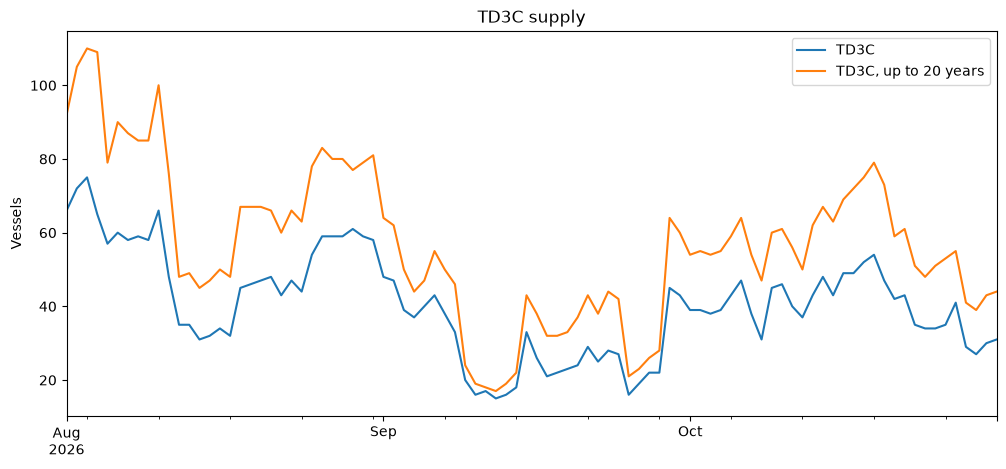

In [8]:
older = SupplyFilter(
    vessel_particulars=VesselParticularsFilter(vessel_age=MinMaxRange(max=20))
)
older_frame = api.get_supply_trend(date(2026, 8, 1), date(2026, 10, 31), template="TD3C", filters=older).to_data_frame()

comparison = pd.DataFrame({
    "TD3C": trend_frame["supply"],
    "TD3C, up to 20 years": older_frame["supply"],
})
comparison.plot(figsize=(12, 5), title="TD3C supply", ylabel="Vessels", xlabel="")

In [9]:
connection.close()